In [1]:
%pip install -qU duckduckgo-search langchain-community

Note: you may need to restart the kernel to use updated packages.


In [37]:
from langchain_community.tools import DuckDuckGoSearchRun

from langchain_community.tools import DuckDuckGoSearchResults

search = DuckDuckGoSearchRun()
# search = DuckDuckGoSearchResults(output_format="json")


response = search.invoke("Obama's first name?")

In [38]:
search.invoke("past tense of german kommen")

'Kommen conjugation, a fundamental aspect of German grammar, varies significantly across different tenses such as present, past, and future. Mastering its usage, including forms like "ich komme" in the present and "ich kam" in the past, is crucial for achieving fluency in German. Committing these conjugations to memory enhances your ability to construct sentences accurately and communicate ... One of the first German verbs you should learn is the infinitive verb "kommen," which means "to come" in English. Speaking and writing in everyday German requires using the common verb "kommen" in various tenses and moods. It can be challenging to learn "kommen" because German verbs have more conjugation options than English verbs. Master all 6 German tenses with clear explanations, conjugation tables, and examples. Test your knowledge with free quizzes and exercises! Use in Perfect and Past Perfect Tense (Perfekt & Plusquamperfekt) German uses haben or sein as auxiliary verbs in the present perf

In [39]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.1",
    temperature=0,
    num_threads=29,
    num_gpu=0
 )
# response = llm.invoke("hey")
# print(type(response))


In [102]:
tool = DuckDuckGoSearchResults(output_format="string")
tools = [tool]
# tools = [DuckDuckGoSearchResults(output_format="json")]

# tools = [DuckDuckGoSearchRun()]
# model_with_tools = llm.bind_tools([multiply], tool_choice="multiply")
# llm_with_tools = llm.bind_tools(tools)
# print(llm_with_tools)

In [114]:
# from langgraph.prebuilt import create_react_agent
from langchain_core.prompts import PromptTemplate


from langchain.agents import AgentExecutor, create_react_agent

from langchain import hub
from langchain_community.llms import OpenAI
from langchain.agents import AgentExecutor, create_react_agent

prompt_template: str = """/
Given the user request: "{query}", determine if using a tool (e.g., web, Python, image generation, or file handling) is required. If a tool is needed, use it appropriately to provide the most accurate and helpful response.

Think through the task step-by-step:
1. Understand what the user is asking.
2. Check if internal knowledge is sufficient (up to [insert knowledge cutoff date]).
3. If up-to-date or external information is required, or the task involves calculations or image manipulation, use the correct tool.
4. Present the final response clearly, combining tool output and reasoning.

Only use tools if necessary.
"""

prompt = PromptTemplate.from_template(template=prompt_template)

# prompt = hub.pull("hwchase17/react")

agent = create_react_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools)

# agent_executor.invoke({"input": "hi"})

agent.invoke({ "query" : "all verb konjugation of kommen in german"})

ValueError: Prompt missing required variables: {'tool_names', 'tools', 'agent_scratchpad'}

In [125]:
%pip install -qU langchain-tavily

Note: you may need to restart the kernel to use updated packages.


In [126]:
import os
os.environ["TAVILY_API_KEY"] =  "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"
from langchain_tavily import TavilySearch



In [145]:
from langchain.agents import AgentExecutor, create_react_agent
from langchain.prompts import PromptTemplate
from langchain.tools import Tool

prompt_template = """
You are an intelligent AI assistant capable of using tools such as {tool_names}.

Given the user request: "{input}", determine whether a tool (from the available list) is required. Use it appropriately if needed.

Step-by-step reasoning:
1. Understand the user's request.
2. Decide whether your internal knowledge is enough (knowledge cutoff: [insert cutoff date]).
3. If not, use the appropriate tool among: {tools}.
4. Record your reasoning, actions, and final answer.

Begin now.

{agent_scratchpad}
"""

prompt = PromptTemplate.from_template(template=prompt_template)

# Now use this prompt to create your agent
agent = create_react_agent(llm, tools=tools, prompt=prompt,)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True)


In [147]:
from langchain_tavily import TavilySearch
from langgraph.prebuilt import create_react_agent
from pydantic import BaseModel, Field 
from typing import Annotated, Optional,  Literal, List, NewType
from typing_extensions import TypedDict


# Initialize Tavily Search Tool
tavily_search_tool = TavilySearch(
    max_results=5,
    topic="general",
)

class GermanVerbsDetails(BaseModel):
    """State to manage conjugation of single verb given"""
    infinitive: str = Field(...,
                            description="""An Infintive form of 
                            the given string in German
                            """)
    # infinitive: String = Field(...,
    #                         description="""An Infintive form of 
    #                         the given string in German
    #                         """)
    
    singular_present_tense: List[str] = Field(...,
                            description="""The 3rd person singular used in present tense
                            for the given verb in German. 
                            """)
    simple_past: List[str] = Field(...,
                             description="""The simple past for the given verb in German. 
                             """)
    present_perfect: List[str] = Field(...,
                             description="""The present perfect tense for the given verb in German.
                             """)
    # is_separable: Boolean
    # is_separable: Boolean = Field(...,
    #                            description="""Wheather the verb is separable or inseparable? True
    #                            if it's seperable else False
    #                            """)
    # # is_regular: Boolean
    # is_regular: Boolean = Field(...,
    #                          description=""" Whather the verb is regular or irregular verb? True if
    #                          it's regular else False""")
    is_separable: bool = Field(...,
                               description="""Wheather the verb is separable or inseparable? True
                               if it's seperable else False
                               """)
    # is_regular: Boolean
    is_regular: bool = Field(...,
                             description=""" Whather the verb is regular or irregular verb? True if
                             it's regular else False""")
    
    english_alternative: List[str] = Field(...,
                             description="""The English translation for the given verb. 
                             """)


agent = create_react_agent(llm, [tavily_search_tool], response_format=GermanVerbsDetails)

user_input = "all verb konjugation of kommen in german"
res = agent.invoke({"messages": user_input})


In [154]:
print(res["messages"][-1].content)

The verb "kommen" (to come) has the following conjugations in German:

* Present:
	+ Ich komme
	+ Du kommst/kömmst
	+ Er/Sie/Es kommt/kömmt
	+ Wir kommen
	+ Ihr kommt
	+ Sie kommen
* Past (Präteritum):
	+ Ich kam
	+ Du kamst
	+ Er/Sie/Es kam
	+ Wir kamen
	+ Ihr kamt
	+ Sie kamen
* Future I:
	+ Ich werde kommen
	+ Du wirst kommen
	+ Er/Sie/Es wird kommen
	+ Wir werden kommen
	+ Ihr werdet kommen
	+ Sie werden kommen
* Perfect (Perfekt):
	+ Ich bin gekommen
	+ Du bist gekommen
	+ Er/Sie/Es ist gekommen
	+ Wir sind gekommen
	+ Ihr seid gekommen
	+ Sie sind gekommen

Note that the conjugation of "kommen" can vary depending on the tense and person.


In [137]:
from langchain_tavily import TavilySearch
from langgraph.prebuilt import create_react_agent

# Initialize Tavily Search Tool
tavily_search_tool = TavilySearch(
    max_results=5,
    topic="general",
)


ddg_raw_tool = DuckDuckGoSearchResults(output_format="string")
agent = create_react_agent(llm, [ddg_raw_tool])

user_input = """

 
 
 """

user_input = " all verb konjugation of kommen in german"

for step in agent.stream(
    {"messages": user_input},
    stream_mode="values",):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

 all verb konjugation of kommen in german
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_results_json (7e93ec9b-cffb-4403-b477-e675d79885e5)
 Call ID: 7e93ec9b-cffb-4403-b477-e675d79885e5
  Args:
    query: german all verb conjugation kommen
================================= Tool Message =================================
Name: duckduckgo_results_json

snippet: Click here to join Entri Elevate and learn all German Kommen Conjugation forms! Join now! German Kommen Conjugation: Introduction "Kommen" conjugations mean "I come," "I came," "I will come," and so on. One of the first German verbs you should learn is the infinitive verb "kommen," which means "to come" in English., title: German Kommen Conjugation - Entri Blog, link: https://entri.app/blog/german-kommen-conjugation/, snippet: The Basics of German Kommen Conjugation. Before diving into the s

In [131]:
from langchain_community.tools.youtube.search import YouTubeSearchTool
from langchain.agents import AgentExecutor, create_react_agent
from langchain.prompts import PromptTemplate
from langchain.tools import Tool
from langchain.chat_models import ChatOpenAI  # Or OpenAI for completions

# Step 1: Initialize the raw tool
yt_raw_tool = YouTubeSearchTool()

# Step 2: Wrap it with Tool for LangChain agent compatibility
yt_tool = Tool(
    name="YouTubeSearch",
    func=yt_raw_tool.run,
    description="Use this to search for YouTube videos on a given topic. Input should be a search query like 'latest GPT-4 updates'."
)

tools = [yt_tool]

# Step 4: Define the custom ReAct-style prompt
prompt_template = """
You are an intelligent AI assistant capable of using tools such as {tool_names}.

Given the user request: "{input}", determine whether a tool (from the available list) is required. Use it appropriately if needed.

Step-by-step reasoning:
1. Understand the user's request.
2. Decide whether your internal knowledge is enough (knowledge cutoff: 2024-06).
3. If not, use the appropriate tool among: {tools}.
4. Record your reasoning, actions, and final answer.

Begin now.

{agent_scratchpad}
"""

prompt = PromptTemplate.from_template(template=prompt_template)

# Step 5: Create the agent
agent = create_react_agent(llm=llm, tools=tools, prompt=prompt)

# Step 6: Create the agent executor
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True)

# Step 7: Run the agent
response = agent_executor.invoke({"input": "Find the latest videos songs"})
print(response)




> Entering new AgentExecutor chain...


ValueError: An output parsing error occurred. In order to pass this error back to the agent and have it try again, pass `handle_parsing_errors=True` to the AgentExecutor. This is the error: Could not parse LLM output: `**Step 1: Understand the user's request**
The user has requested "Find the latest videos songs".

**Step 2: Decide whether internal knowledge is enough**
My knowledge cutoff is 2024-06, but I don't have real-time information about the latest music releases or videos. Therefore, I need to use an external tool to find the latest videos.

**Step 3: Use the appropriate tool (YouTubeSearch)**
I will use the YouTubeSearch tool to search for the latest video songs. The input should be a search query like "latest song updates" or "new music releases".

Here's how I'll use the tool:
```python
from youtubesearchpython import VideosSearch

vs = VideosSearch("latest videos songs", limit=10)
results = vs.result()
```
This will return a list of the latest video songs based on the sear

In [134]:
from langchain.tools import Tool
from langchain.tools.ddg_search.tool import DuckDuckGoSearchResults

ddg_raw_tool = DuckDuckGoSearchResults(output_format="string")
tool = TavilySearch(
    max_results=5,
    topic="general")

ddg_tool = Tool(
    name="DuckDuckGoSearch",
    func=ddg_raw_tool.run,
    description="Useful for answering questions about current events or anything that requires real-time information from the web."
)

tavily_tool = Tool(
    name="Tavily api",
    func=ddg_raw_tool.run,
    description="Useful for answering questions about current events or anything that requires real-time information from the web."
)



tools = [tavily_tool]

prompt_template = """
You are an intelligent AI assistant capable of using tools such as {tool_names}.

Given the user request: "{input}", determine whether a tool (from the available list) is required. Use it appropriately if needed.

Step-by-step reasoning:
1. Understand the user's request.
2. Decide whether your internal knowledge is enough (knowledge cutoff: 2024-06).
3. If not, use the appropriate tool among: {tools}.
4. Record your reasoning, actions, and final answer.



Begin now.

{agent_scratchpad}
"""

prompt = PromptTemplate.from_template(template=prompt_template)
agent = create_react_agent(llm=llm, tools=tools, prompt=prompt)
agent_executor = AgentExecutor(agent=agent,
                               tools=tools,
                               verbose=True,
                               handle_parsing_errors=True)

In [135]:
response = agent_executor.invoke({"input": "all verb konjugation of kommen in german"})
print(response)



> Entering new AgentExecutor chain...
**Step 1: Understand the user's request**

The user has requested "all verb conjugation of kommen in German". This is a language-related question, specifically asking for the conjugations of the German verb "kommen" (to come).

**Step 2: Decide whether internal knowledge is enough**

My internal knowledge cutoff is 2024-06. While I have a vast amount of knowledge about languages, including German grammar and verb conjugation, my knowledge may not be exhaustive or up-to-date on very specific or nuanced aspects of the language.

However, for basic verb conjugations, my internal knowledge should be sufficient.

**Step 3: Determine if a tool is required**

Upon reviewing my internal knowledge, I realize that while I can provide some general information about German verb conjugation, I may not have detailed and accurate conjugations for every possible tense, mood, and person. In this case, using an external tool like Tavily API could be beneficial to 

KeyboardInterrupt: 

In [ ]:

agent.invoke({ "input" : "all verb konjugation of kommen in german"})

In [43]:
model_response = llm_with_tools.invoke("verb konjugation of kommen in german")

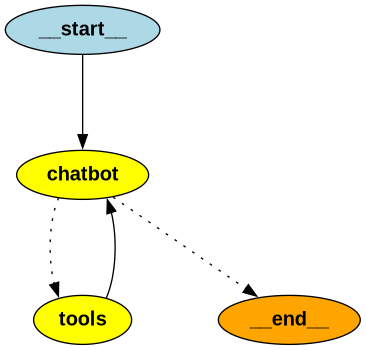

In [103]:
from IPython.display import Image, display

from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Annotated, TypedDict

class State(TypedDict):
    query: str
    results: str
    
def chatbot(state: State):
    print(llm_with_tools.invoke(state["query"]))
    return {"results": llm_with_tools.invoke(state["query"]).content}


graph_builder = StateGraph(State)
# Add the chatbot node to the graph
graph_builder.add_node("chatbot", chatbot)
# Add a node to handle tool invocations
graph_builder.add_node("tools", ToolNode(tools))

# Set up control flow:
# After the chatbot node, check if a tool call is needed.
# If so, route to the "tools" node, then return to the chatbot.
graph_builder.add_conditional_edges("chatbot", tools_condition)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

# Compile the graph into an executable object
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_png()))


In [104]:
model_response = graph.invoke({"query": "all verb konjugation of kommen in german"})

content='' additional_kwargs={} response_metadata={'model': 'llama3.1', 'created_at': '2025-04-22T11:00:42.455602169Z', 'done': True, 'done_reason': 'stop', 'total_duration': 10642098114, 'load_duration': 4048585550, 'prompt_eval_count': 191, 'prompt_eval_duration': 4466613864, 'eval_count': 26, 'eval_duration': 2123457218, 'model_name': 'llama3.1'} id='run-7ad8fe34-3fae-4d08-b624-fc095a2a6221-0' tool_calls=[{'name': 'duckduckgo_results_json', 'args': {'query': 'german all verb conjugation kommen'}, 'id': 'af0b905e-e48c-4dee-a59d-0c18e8569eaa', 'type': 'tool_call'}] usage_metadata={'input_tokens': 191, 'output_tokens': 26, 'total_tokens': 217}


ValueError: No messages found in input state to tool_edge: {'results': '', 'query': 'all verb konjugation of kommen in german'}

In [ ]:
model_response

In [75]:
# from duckduckgo_search import ddg

def duckduckgo_search_tool(query: str):
    search = DuckDuckGoSearchRun()
    results = search.invoke(query)
    return results
    # results = ddg(query, max_results=3)
    # return "\n".join([r["href"] + " - " + r["body"] for r in results])

In [99]:
def search_node(state):
    query = state["query"]
    search_results = duckduckgo_search_tool(query)
    return {"answer": search_results}

def llm_node(state):
    query = state["query"]
    response = llm.invoke(f"Given the query: '{query}', do we need to search the web? Answer yes or no.")
    print(response)
    if "yes" in response.content.lower():
        return {"next_step": "search"}
    else:
        final_response = llm.invoke(f"Answer this without web search: {query}")
        return {"answer": final_response, "next_step": "end"}

In [100]:
from langgraph.graph import StateGraph, END

class State(TypedDict):
    query: str
    results: str
    answer: str
    
graph = StateGraph(State)

graph.add_node("llm_decide", llm_node)
graph.add_node("search", search_node)

# Logic for flow
def route_decision(state):
    return state["next_step"]

graph.set_entry_point("llm_decide")
graph.add_conditional_edges("llm_decide", route_decision, {
    "search": "search",
    "end": END
})
graph.add_edge("search", END)

agent = graph.compile()


In [101]:
initial_state = {"query": "What is the latest news about SpaceX?"}
result = agent.invoke(initial_state)
print(result)

content='Yes.' additional_kwargs={} response_metadata={'model': 'llama3.1', 'created_at': '2025-04-22T10:26:36.191086615Z', 'done': True, 'done_reason': 'stop', 'total_duration': 336797430, 'load_duration': 19793107, 'prompt_eval_count': 36, 'prompt_eval_duration': 111185723, 'eval_count': 3, 'eval_duration': 205233751, 'model_name': 'llama3.1'} id='run-000532fb-55e2-4b42-a735-c156ccc9c3e9-0' usage_metadata={'input_tokens': 36, 'output_tokens': 3, 'total_tokens': 39}
{'query': 'What is the latest news about SpaceX?', 'answer': 'A SpaceX Falcon 9 rocket will launch a robotic Dragon cargo ship to the International Space Station early Monday morning (April 21), and you can watch the action live. ... Latest in News. SpaceX was not happy with the news. On Sept. 10, the company published a blog post titled " Starships Are Meant to Fly ," which claimed that the FAA had previously given SpaceX a mid-September ... SpaceX discontinued its video feed of the launch without providing a location for